# 06 · Chapter 4: harder tasks
Problems where small panels should fail: adenocarcinoma vs squamous lung cancer, breast PAM50 subtypes, and pan-cancer tissue of origin.

In [1]:
import os, glob
os.chdir('..') if os.path.basename(os.getcwd()) == 'notebooks' else None
import pandas as pd
from IPython.display import Image, display
pd.set_option('display.precision', 3); pd.set_option('display.max_rows', 80)
R = 'results/harder'
TAB, FIG = f'{R}/tables', f'{R}/figures'
summary = pd.read_csv(f'{TAB}/summary.csv')
best = lambda k: (summary[(summary.model == 'logreg') & (summary.k == k) & ~summary.selector.isin(['random', 'variance', 'all_genes'])]
                  .groupby(['cancer', 'task']).auc_mean.max().rename(f'best_{k}'))

## Minimal panel per task
Smallest panel that is non-inferior to all genes (corrected repeated-CV test), and the smallest reaching 90% sensitivity at 95% specificity.

In [2]:
pd.read_csv(f'{TAB}/minimal_panel.csv')

,cancer,task,model,n_genes_all,auc_all_genes,auc_best_1,auc_best_10,smallest_retained_k,auc_random_10,smallest_k_sens90,sens_all_genes
0,BRCA,pam50_subtype,logreg,17623,0.984,0.829,0.960,50.0,0.820,NaN,NaN
1,LUAD_LUSC,adeno_vs_squamous,logreg,18080,0.989,0.973,0.991,5.0,0.896,1.0,0.964
2,TCGA12,tissue_of_origin,logreg,13762,0.999,0.840,0.997,10.0,0.947,NaN,NaN


## AUC as the panel shrinks (logistic regression)

In [3]:
allg = summary[(summary.model == 'logreg') & (summary.selector == 'all_genes')].set_index(['cancer', 'task']).auc_mean.rename('all_genes')
rnd = summary[(summary.model == 'logreg') & (summary.selector == 'random') & (summary.k == 10)].set_index(['cancer', 'task']).auc_mean.rename('random_10')
pd.concat([allg, best(500), best(50), best(10), best(5), best(1), rnd], axis=1)

,,all_genes,best_500,best_50,best_10,best_5,best_1,random_10
cancer,task,,,,,,,
BRCA,pam50_subtype,0.984,0.988,0.984,0.960,0.951,0.829,0.820
LUAD_LUSC,adeno_vs_squamous,0.989,0.988,0.990,0.991,0.989,0.973,0.896
TCGA12,tissue_of_origin,0.999,0.999,0.999,0.997,0.983,0.840,0.947


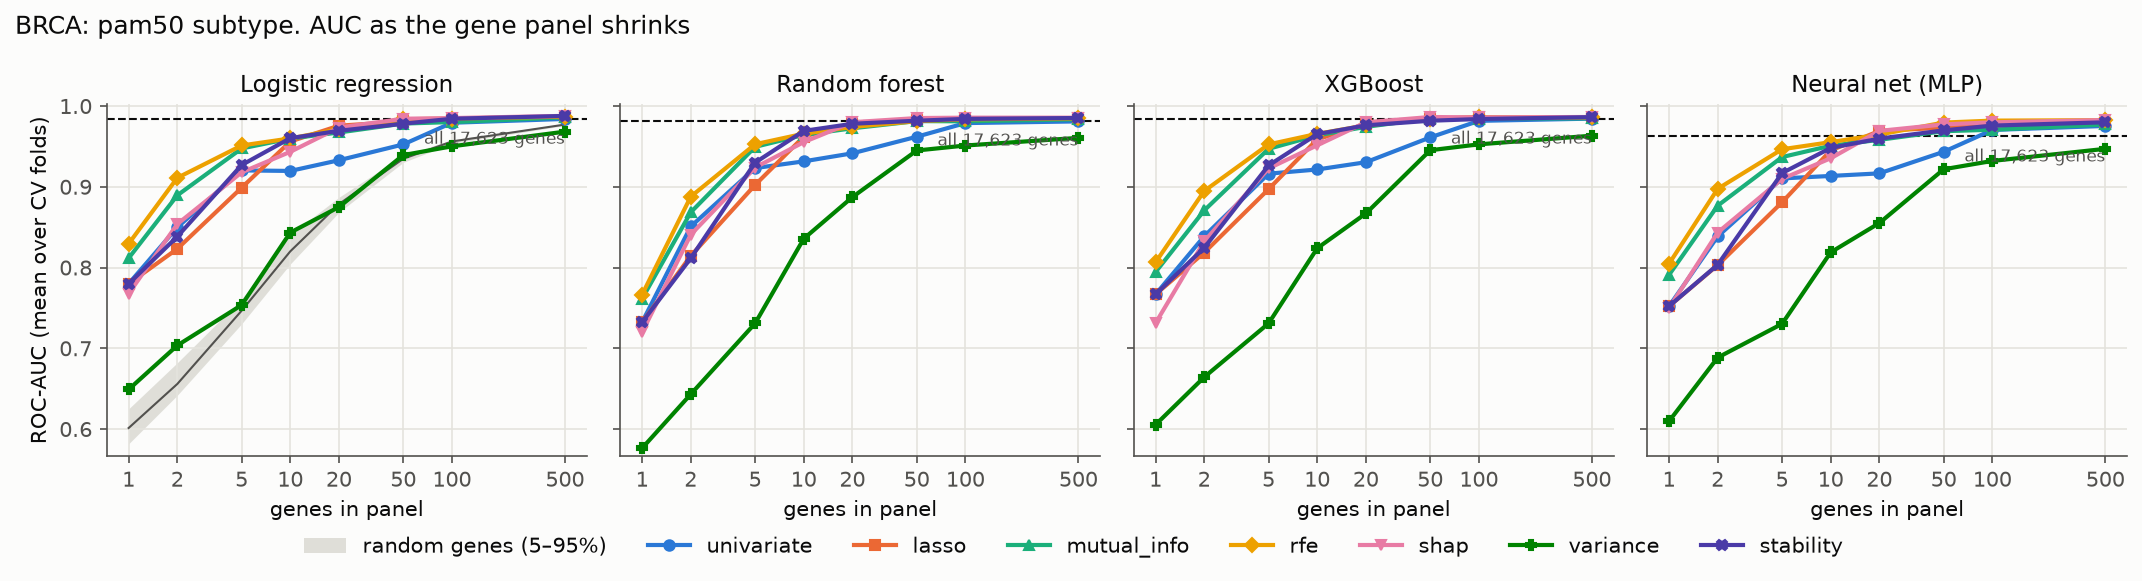

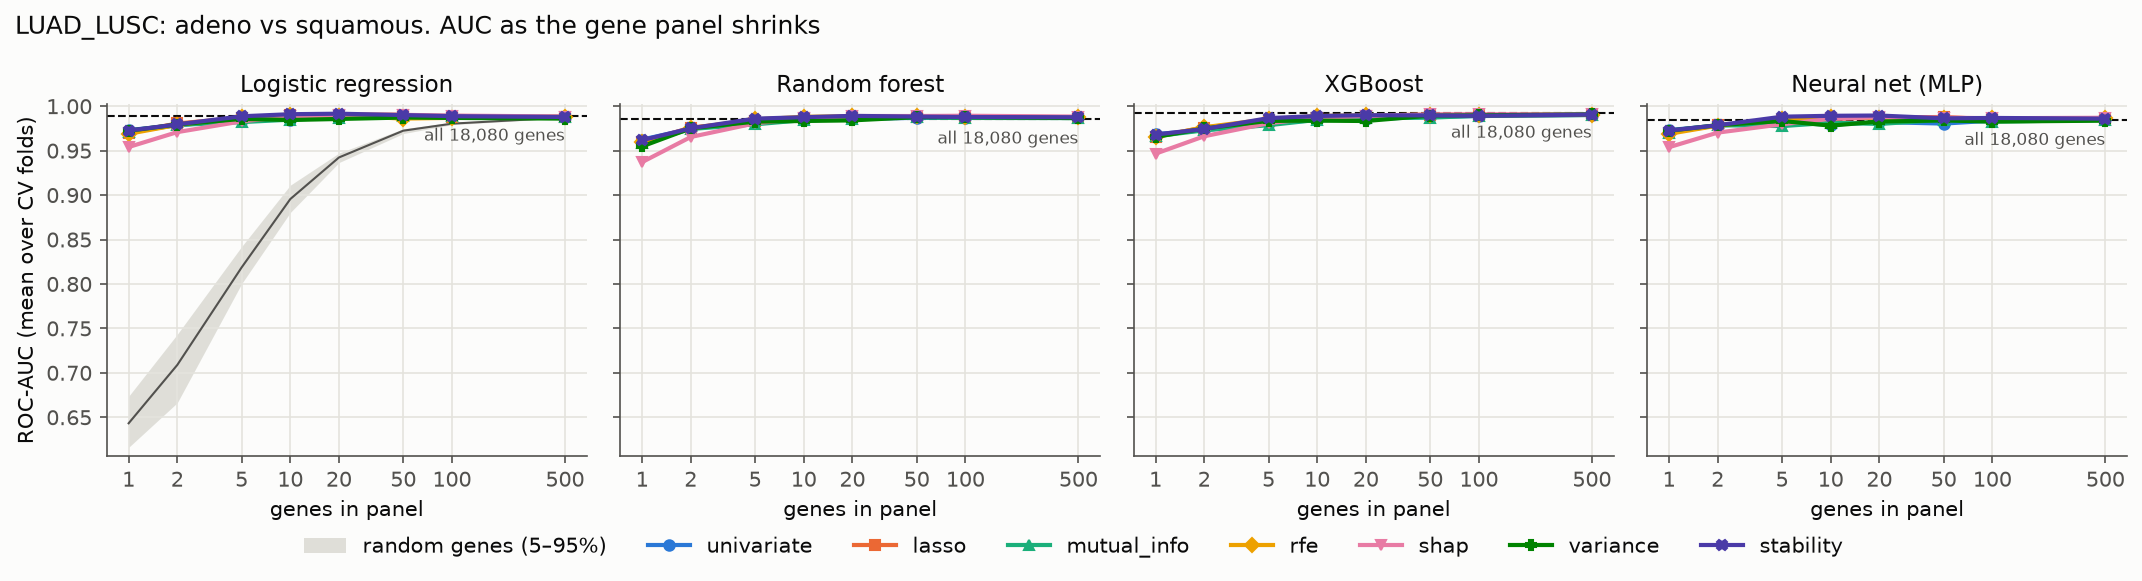

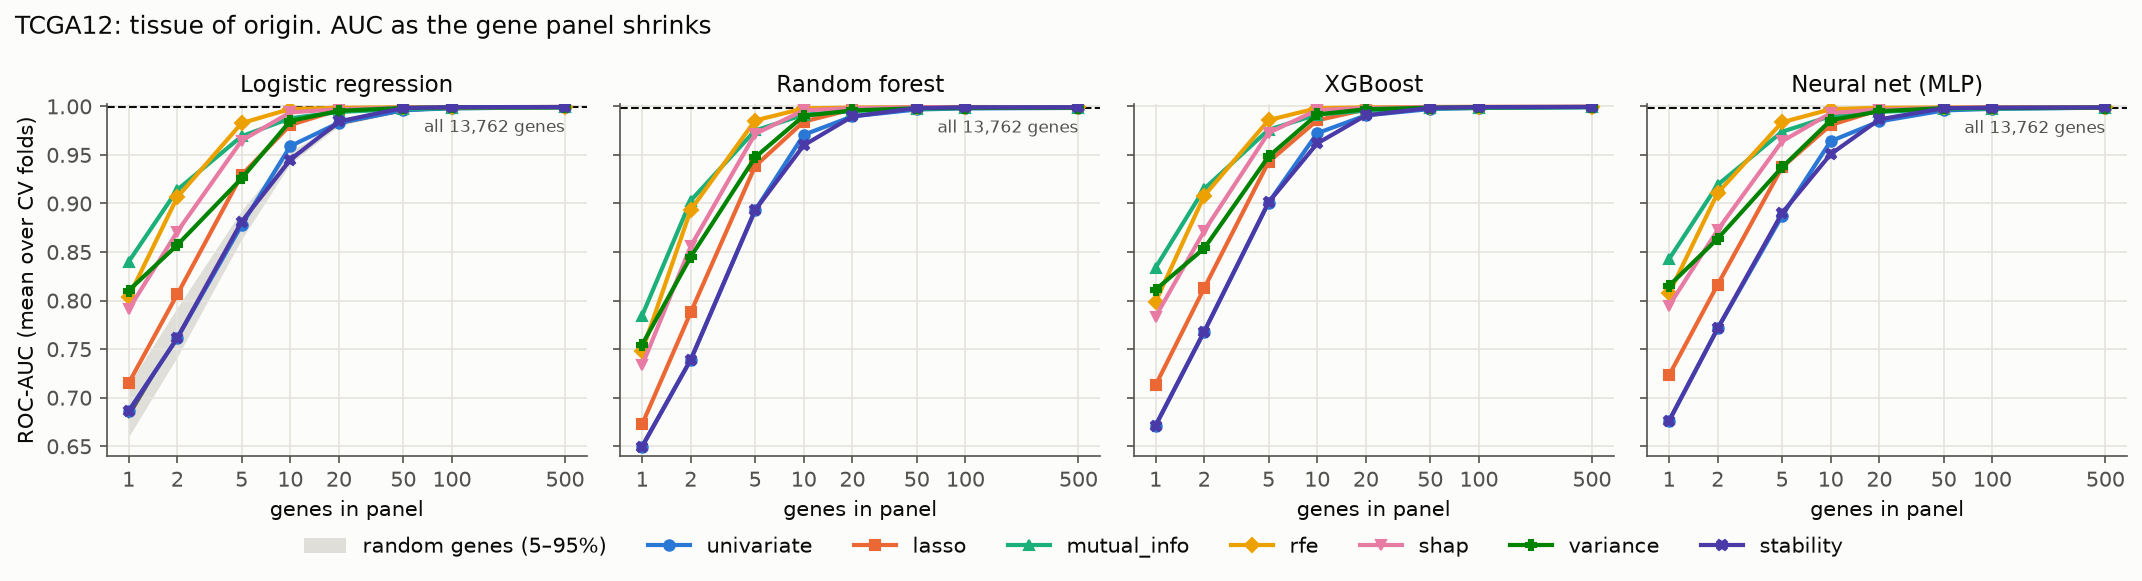

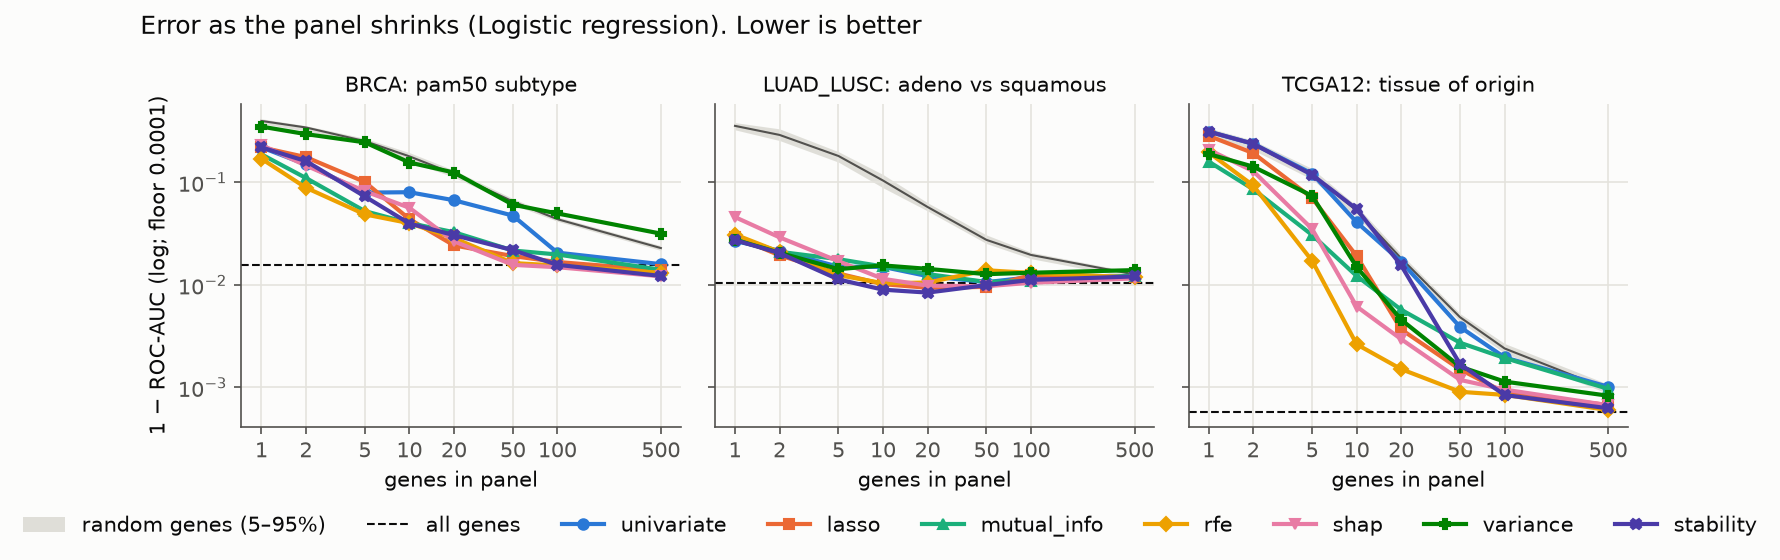

In [4]:
for f in sorted(glob.glob(f'{FIG}/auc_vs_k_*.png')) + [f'{FIG}/error_vs_k_logreg.png']:
    display(Image(f))

## Consensus genes

In [5]:
cons = pd.read_csv(f'{TAB}/consensus.csv')
cons[cons.panel == 'consensus10'][['cancer', 'task', 'gene', 'freq']]

,cancer,task,gene,freq
9507,BRCA,pam50_subtype,FOXC1,0.800
9508,BRCA,pam50_subtype,MLPH,0.780
9509,BRCA,pam50_subtype,FOXA1,0.673
9510,BRCA,pam50_subtype,ESR1,0.640
9511,BRCA,pam50_subtype,TBC1D9,0.340
9512,BRCA,pam50_subtype,CENPN,0.293
9513,BRCA,pam50_subtype,C6orf97,0.253
9514,BRCA,pam50_subtype,ERBB2,0.253
9515,BRCA,pam50_subtype,AGR3,0.247
9516,BRCA,pam50_subtype,CENPA,0.220
